In [2]:
'''
-Matplotlib
-Seaborn
-Plotly

1.Analysis
 a.Bar Chart
 b.Line Chart
 c.Column chart
 d.Pie chart 
 e.Donut chart 


2. Statistical Chart
 A. Histogram
 B.Box plot 
 c. COrrelation Heatmaps
 d. Violin Plot


'''

'\n-Matplotlib\n-Seaborn\n-Plotly\n\n1.Analysis\n a.Bar Chart\n b.Line Chart\n c.Column chart\n d.Pie chart \n e.Donut chart \n\n\n2. Statistical Chart\n A. Histogram\n B.Box plot \n c. COrrelation Heatmaps\n d. Violin Plot\n\n\n'

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import plotly.express as px

In [4]:
employees = ['Bob','Arthur','Dutch','Xavier','Bill']
salary=[60000,100000,80000,20000,55000]
bonus = [40000,60000,45000,10000,25000]

# Line plot 

In [5]:
def formatDataPoints(val):
    if abs(val)>1e9:
      return f'{val / 1e9:,.2f}B'
    elif abs(val)> 1e6:
        return f'{val / 1e6:,.2f}M'
    elif abs(val)>1e3:
        return f'{val / 1e3:,.2f}K'
    else:
        return f'{val}'

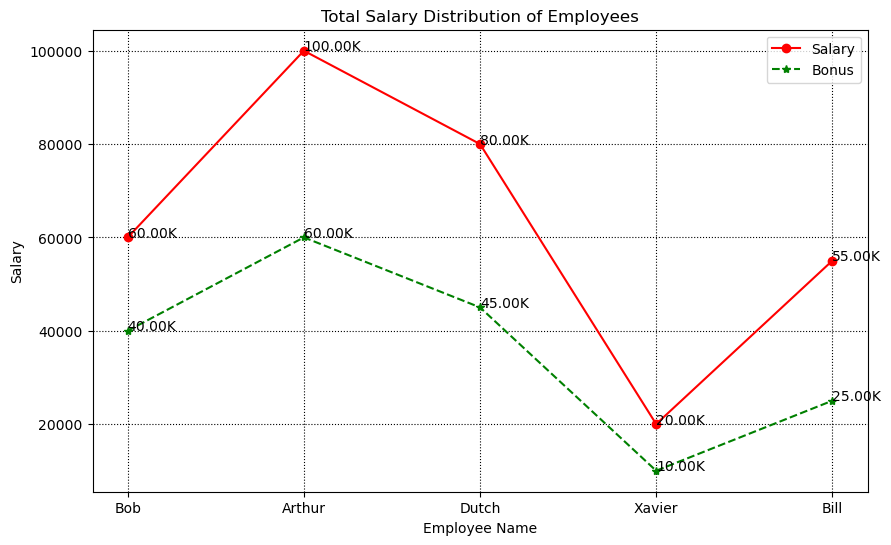

In [6]:
# plt.plot(employees, salary, color='blue')
# or using a hex code:
plt.figure(figsize=(10,6))
plt.plot(employees,salary, color='red',marker = 'o', linestyle='solid',label='Salary')
plt.plot(employees,bonus,color='green',marker='*', linestyle='dashed',label='Bonus')
plt.xlabel('Employee Name')
plt.ylabel('Salary')
plt.title('Total Salary Distribution of Employees')
plt.grid(linestyle='dotted', color='black',alpha=1)
plt.legend()
for idx,val in enumerate(salary):
    formatted_value = formatDataPoints(val)
    plt.text(idx,val,formatted_value)
for idx,val in enumerate(bonus):
    formatted_value = formatDataPoints(val)
    plt.text(idx,val,formatted_value)
plt.savefig('employee_salary_bonus.png')
plt.show()

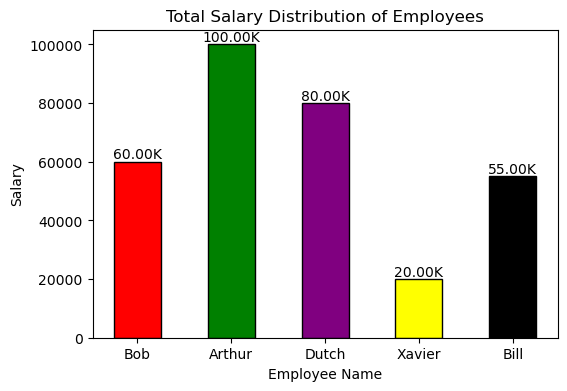

In [7]:
plt.figure(figsize=(6,4))
colors = ['red','green','purple','yellow','black']
plt.bar(employees,salary,color=colors,width=0.5, edgecolor= 'black')
plt.xlabel('Employee Name')
plt.ylabel('Salary')
plt.title('Total Salary Distribution of Employees')
for idx,val in enumerate(salary):
    formatted_value = formatDataPoints(val)
    plt.text(idx,val,formatted_value, ha='center',va='bottom')

plt.show()

# Scatter Plot

In [8]:
temp = pd.read_csv('Dataset/temperature.csv')
temp.head()

,Temperature (°C),Humidity (%)
0,23.745401,57.186649
1,29.507143,66.765614
2,27.319939,64.034868
3,25.986585,60.921443
4,21.560186,49.099373


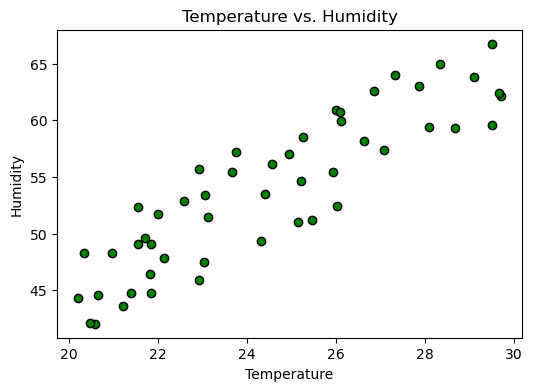

In [9]:
plt.figure(figsize =(6,4))
plt.scatter(temp['Temperature (°C)'],temp['Humidity (%)'],color='green',edgecolor='black')
plt.xlabel('Temperature')
plt.ylabel('Humidity')
plt.title('Temperature vs. Humidity')
plt.show()

In [10]:
df = pd.read_csv('cleaned_hr.csv')
df.head()

,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,...,Month_name,Day_name,Salary_Label,sal_id,Salary_Label_id,Sal_First,Sal_Last,First_Name,Last_Name,Middle_Name
0,Bacong Alejandro,10250,0,2,1,1,3,3,0,50178,...,January,Monday,Low Salary,0,0,Low,Salary,Alejandro,Bacong,NaN
1,Baczenski Rachael,10252,1,1,0,5,5,3,1,54670,...,January,Monday,Low Salary,0,0,Low,Salary,Rachael,Baczenski,NaN
2,Barbara Thomas,10242,1,1,1,5,5,3,1,47211,...,April,Monday,Low Salary,0,0,Low,Salary,Thomas,Barbara,NaN
3,Barbossa Hector,10012,0,2,1,1,3,4,1,92328,...,November,Monday,Average Salary,1,1,Average,Salary,Hector,Barbossa,NaN
4,Barone Francesco A,10265,0,0,1,1,5,3,0,58709,...,February,Monday,Low Salary,0,0,Low,Salary,Francesco,Barone,A


In [11]:
df.columns

Index(['Employee_Name', 'EmpID', 'MarriedID', 'MaritalStatusID', 'GenderID',
       'EmpStatusID', 'DeptID', 'PerfScoreID', 'FromDiversityJobFairID',
       'Salary', 'Termd', 'PositionID', 'Position', 'State', 'Zip', 'DOB',
       'Gender', 'MaritalDesc', 'CitizenDesc', 'HispanicLatino', 'RaceDesc',
       'DateofHire', 'DateofTermination', 'TermReason', 'EmploymentStatus',
       'Department', 'ManagerName', 'ManagerID', 'RecruitmentSource',
       'PerformanceScore', 'EngagementSurvey', 'EmpSatisfaction',
       'SpecialProjectsCount', 'LastPerformanceReview_Date', 'DaysLateLast30',
       'Absences', 'Hire_Year', 'Hire_Month', 'Hire_Day', 'Month_name',
       'Day_name', 'Salary_Label', 'sal_id', 'Salary_Label_id', 'Sal_First',
       'Sal_Last', 'First_Name', 'Last_Name', 'Middle_Name'],
      dtype='object')

In [12]:
df['PerformanceScore'].unique()

array(['Fully Meets', 'Exceeds', 'Needs Improvement', 'PIP'], dtype=object)

# pie chart

In [13]:
emp_performance = df.groupby('PerformanceScore')['EmpID'].count().reset_index().rename(
 columns = {'PerformanceScore': 'Performance Score','EmpID':'Total Employee'}
    
)
emp_performance

,Performance Score,Total Employee
0,Exceeds,37
1,Fully Meets,243
2,Needs Improvement,18
3,PIP,13


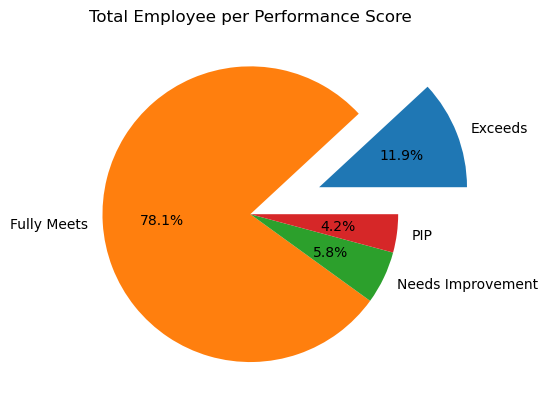

In [14]:
plt.pie(

emp_performance['Total Employee'],
labels=emp_performance['Performance Score'],
    autopct = '%1.1f%%',
    explode=(0.5,0,0,0)
)
plt.title('Total Employee per Performance Score')
plt.show()

# Donut Chart

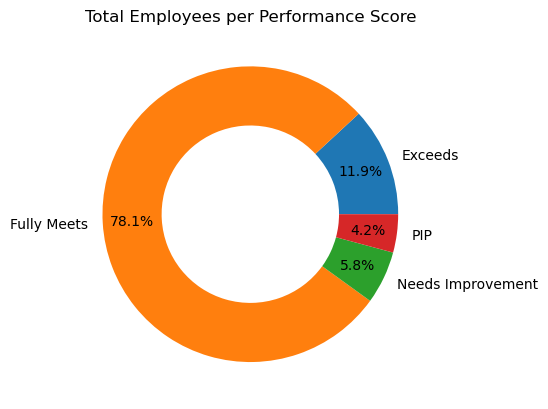

In [15]:
plt.pie(
emp_performance['Total Employee'],
labels=emp_performance['Performance Score'],
    autopct = '%1.1f%%',
   # with edge properties-dic value accepted
    wedgeprops={'width':0.4},
    pctdistance = 0.8
)
plt.title('Total Employees per Performance Score')
plt.show()

### Column Chart

In [16]:
emp_dep = df.groupby(['Department','Gender'])['EmpID'].count().reset_index().rename(
    columns = {'EmpID':'Total Employees'}
)
emp_dep

,Department,Gender,Total Employees
0,Admin Offices,F,6
1,Admin Offices,M,3
2,Executive Office,F,1
3,IT/IS,F,22
4,IT/IS,M,28
5,Production,F,126
6,Production,M,83
7,Sales,F,15
8,Sales,M,16
9,Software Engineering,F,6


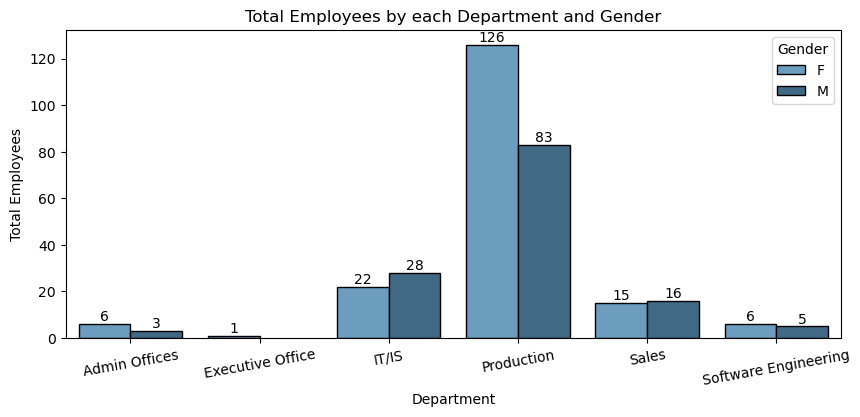

In [17]:
plt.figure(figsize=(10,4))
ax=sns.barplot(data=emp_dep,x='Department',y='Total Employees',hue='Gender',errorbar=None,palette='Blues_d',edgecolor='black')
plt.tick_params(axis='x',rotation=10)
plt.title('Total Employees by each Department and Gender')
for container in ax.containers:
    plt.bar_label(container)
plt.show()

# Statistical Chart

# Histogram

In [18]:
salary_df = df[df['Salary'].between(45000,80000)]

In [19]:
skew=salary_df['Salary'].skew()
mean_salary =df['Salary'].mean()
median_salary=df['Salary'].median()
skew

np.float64(0.048420831309714654)

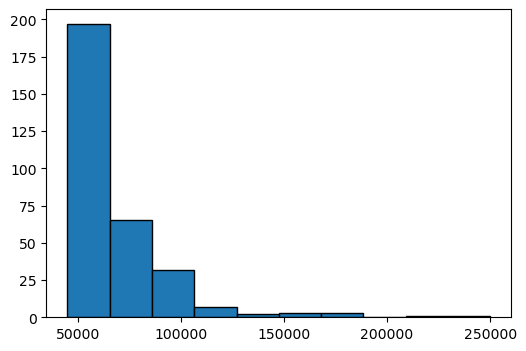

In [20]:

plt.figure(figsize=(6,4))
plt.hist(df['Salary'],edgecolor='black')
plt.show()

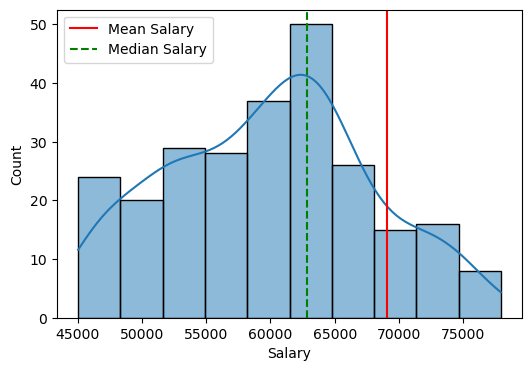

In [21]:
plt.figure(figsize=(6,4))
sns.histplot(salary_df['Salary'], bins=10,kde=True)
#axvline->axis Vertical Line
plt.axvline(mean_salary,color='red',label='Mean Salary')
plt.axvline(median_salary,color='green',linestyle='dashed',label='Median Salary')
plt.legend()
plt.show()

# Box plot

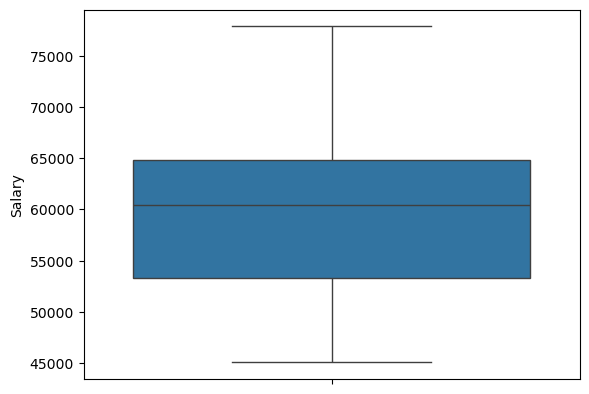

In [22]:
sns.boxplot(salary_df['Salary'])
plt.show()

<Axes: >

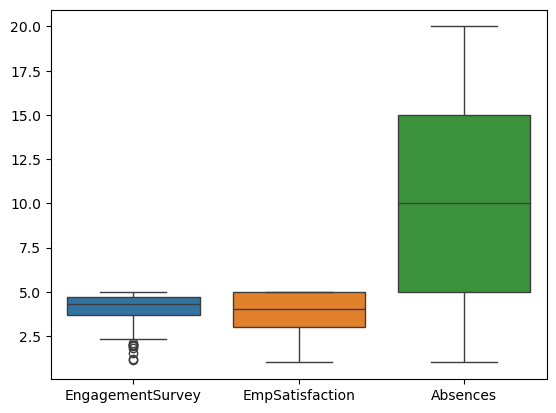

In [23]:
sns.boxplot(
df[['EngagementSurvey','EmpSatisfaction','Absences']]
    )

# Subplots

In [25]:
dep_details = df.groupby('Department').agg(
    Total_Employees =('EmpID','count'),
    Total_Salary = ('Salary','sum'),
    Total_Projects = ('SpecialProjectsCount','sum'),
    Total_Absences =('Absences','sum')
).reset_index()
dep_details

,Department,Total_Employees,Total_Salary,Total_Projects,Total_Absences
0,Admin Offices,9,646127,33,78
1,Executive Office,1,250000,0,10
2,IT/IS,50,4853232,296,522
3,Production,209,12530291,4,2120
4,Sales,31,2140899,0,358
5,Software Engineering,11,1044884,46,96


In [38]:
def  formatDataPoints(val):
    if abs(val) > 1e9:
        return f'{val / 1e9:,.2f}B'
    elif abs(val) > 1e6:
        return f'{val / 1e6:,.2f}M'
    elif abs(val) > 1e3:
        return f'{val / 1e3:,.2f}K'
    else:
        return f'{val}'
def text_data(ax, dataframe, col):
   for idx, val in enumerate(dataframe[col]):
       formatted_data = formatDataPoints(val)
       ax.text(idx,val,formatted_data,ha='center',va='bottom')

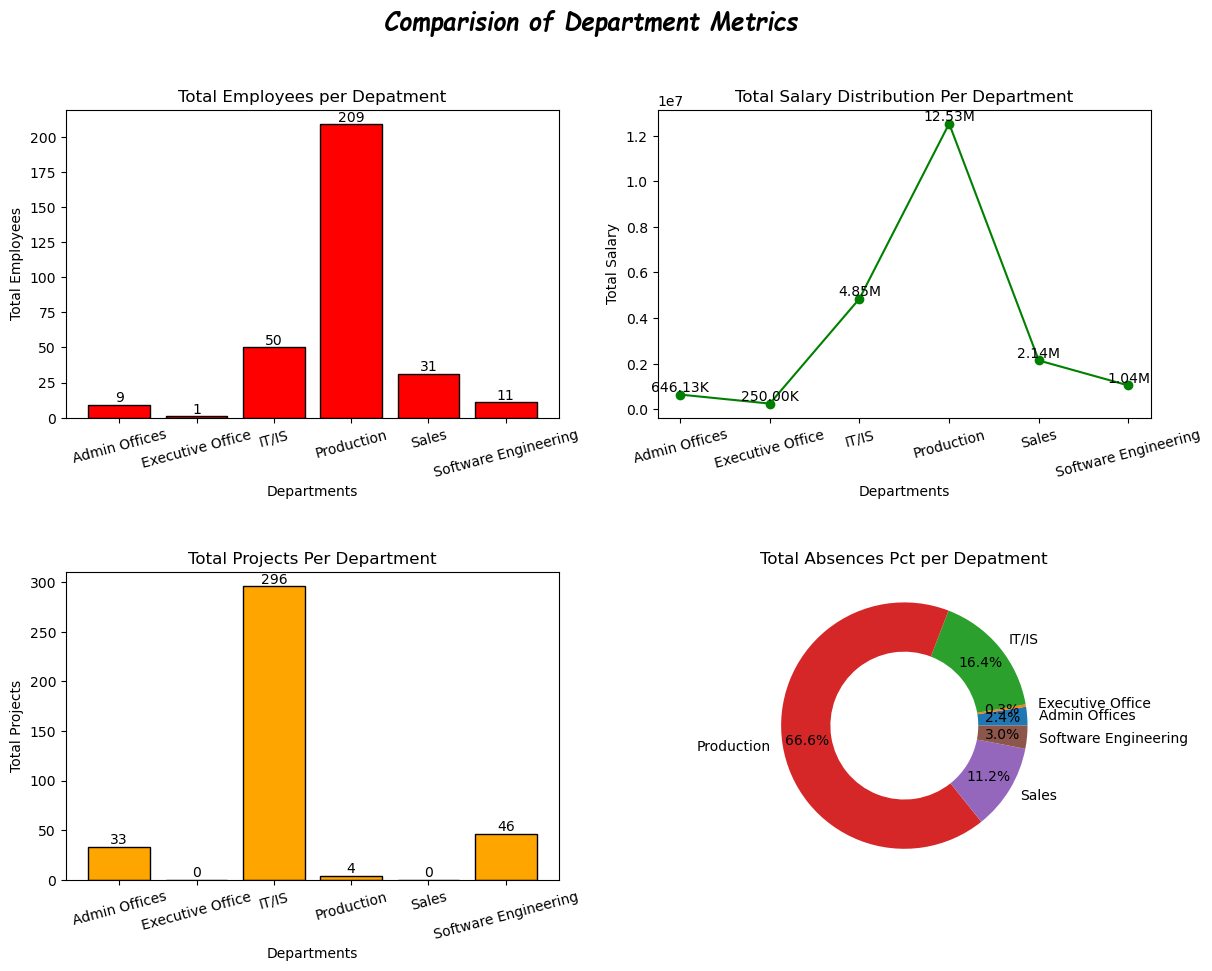

In [59]:
fig,axes = plt.subplots(2,2, figsize=(14,10))
plt.subplots_adjust(hspace=0.5)
plt.suptitle('Comparision of Department Metrics', fontsize='xx-large',fontweight='bold',fontstyle='italic',fontfamily='cursive')

ax1= axes[0,0]
ax1.bar(dep_details['Department'],dep_details['Total_Employees'],color='red',edgecolor='black')
ax1.set_xlabel('Departments')
ax1.set_ylabel('Total Employees')
ax1.set_title('Total Employees per Depatment')
ax1.tick_params(axis='x', rotation=15)
text_data(ax1, dep_details, 'Total_Employees')

ax2 = axes[0,1]
ax2.plot(dep_details['Department'], dep_details['Total_Salary'],marker='o',color='green')
ax2.set_xlabel('Departments')
ax2.set_ylabel('Total Salary')
ax2.set_title('Total Salary Distribution Per Department')
ax2.tick_params(axis='x',rotation=15)
text_data(ax2, dep_details, 'Total_Salary')


ax3 = axes[1,0]
ax3.bar(dep_details['Department'],dep_details['Total_Projects'], color='orange',edgecolor='black')
ax3.set_xlabel('Departments')
ax3.set_ylabel('Total Projects')
ax3.set_title('Total Projects Per Department')
ax3.tick_params(axis='x',rotation=15)
text_data(ax3, dep_details, 'Total_Projects')

ax4= axes[1, 1]
ax4.pie(

    dep_details['Total_Absences'],
    labels = dep_details['Department'],
    autopct='%1.1f%%',
    wedgeprops={'width':0.4},
    pctdistance=0.8
)
ax4.set_title('Total Absences Pct per Depatment')
plt.savefig('subplot.png')
plt.show()

## Correlation Heatmap

In [59]:
'''
1.Pearson Correlation
2.Spearman Correlation
'''

'\n1.Pearson Correlation\n2.Spearman Correlation\n'

In [60]:
data = df.select_dtypes(['int','float'])

In [61]:
data.columns

Index(['EmpID', 'MarriedID', 'MaritalStatusID', 'GenderID', 'EmpStatusID',
       'DeptID', 'PerfScoreID', 'FromDiversityJobFairID', 'Salary', 'Termd',
       'PositionID', 'Zip', 'ManagerID', 'EngagementSurvey', 'EmpSatisfaction',
       'SpecialProjectsCount', 'DaysLateLast30', 'Absences', 'Hire_Year',
       'Hire_Month', 'Hire_Day', 'sal_id', 'Salary_Label_id'],
      dtype='object')

In [62]:
data.drop(columns=['EmpID', 'MarriedID', 'MaritalStatusID', 'GenderID', 'EmpStatusID','ManagerID','FromDiversityJobFairID','Hire_Year','Hire_Month','Hire_Day','sal_id','Salary_Label_id','Termd'],inplace=True)

In [63]:
data_corr=data.corr(method='pearson')

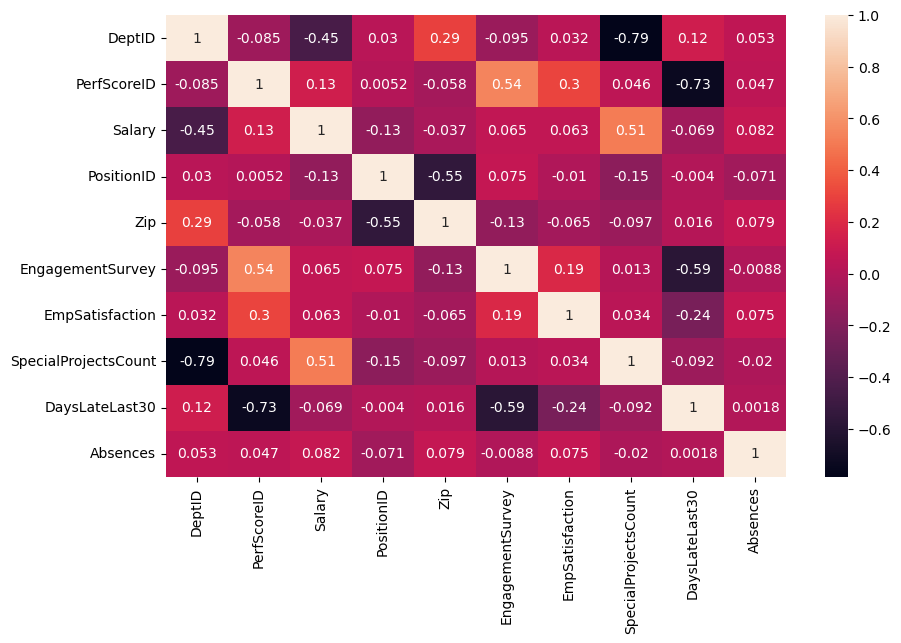

In [64]:
plt.figure(figsize=(10,6))
sns.heatmap(data_corr,annot=True)
plt.show()

# Violin Plot

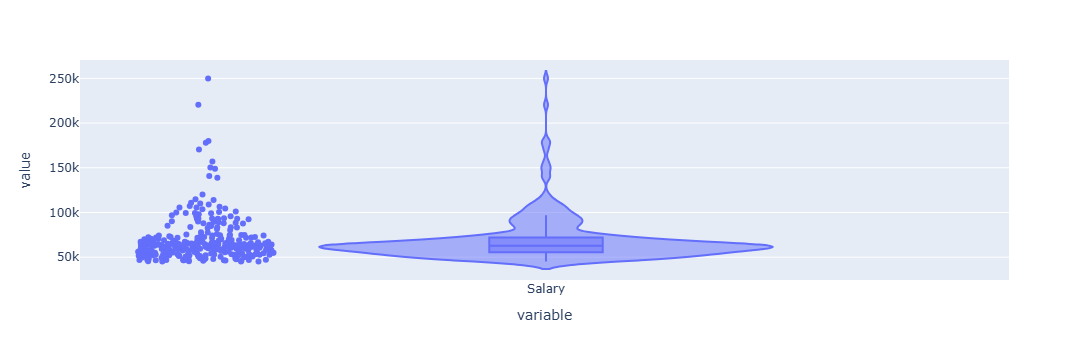

In [67]:
fig=px.violin(
df,
y=['Salary'],
box = True,
points = 'all'
)
fig.show()

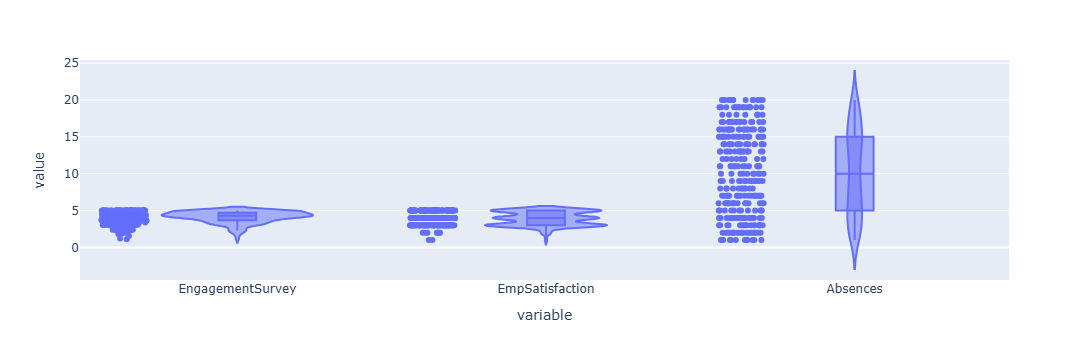

In [73]:
fig = px.violin(
    df,
    y=['EngagementSurvey','EmpSatisfaction','Absences'],
    box = True,
    points = 'all'
)
fig.show()